# Actividad 3 - Ciencia de Datos II

## Modelado supervisado basico e interpretacion del desempeño

**Dataset:** Unidades Deportivas de Cartagena de Indias

**Herramientas:** Python, Pandas, Matplotlib, Jupyter Notebook y Scikit-learn.


### Descripcion

En este notebook se desarrollara el proceso de modelado supervisado utilizando el conjunto de datos de las unidades deportivas de Cartagena de Indias, previamente preparado durante la Actividad 2. Se realizaran operaciones de seleccion de variables, definicion de la variable objetivo, division de los datos en conjuntos de entrenamiento y prueba, construccion y entrenamiento de un modelo de clasificacion, y evaluacion de su desempeño mediante metricas básicas, con el proposito de analizar su capacidad para realizar predicciones e interpretar los resultados obtenidos.

## 1. Importación de librerias

Para el desarrollo de esta actividad se utilizaran diferentes librerias de Python que permitiran realizar el analisis de los datos, construir el modelo de aprendizaje supervisado y evaluar sus resultados. Se empleará Pandas para la manipulacion de la informacion, Matplotlib para la representación grafica y Scikit-learn para la preparacion, entrenamiento y evaluacion del modelo de clasificacion.

In [93]:
# Manipulacion y analisis de datos
import pandas as pd

# Visualizacion de datos
import matplotlib.pyplot as plt

# Division de los datos
from sklearn.model_selection import train_test_split

# Transformacion de variables categoricas
from sklearn.preprocessing import OneHotEncoder

# Organizacion del procesamiento
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelo de clasificacion
from sklearn.tree import DecisionTreeClassifier

# Metricas de evaluacion
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Carga del conjunto de datos

Para el desarrollo del modelado supervisado se utilizara el conjunto de datos de las unidades deportivas de Cartagena de Indias, preparado durante la Actividad 2. Este archivo contiene informacion previamente explorada y depurada, incluyendo caracteristicas relacionadas con los escenarios deportivos, su clasificacion, ubicacion y superficie.

Inicialmente, se realizara la carga del archivo mediante Pandas y se comprobara su estructura, dimensiones, nombres de columnas y tipos de datos, con el proposito de verificar que la información se encuentre disponible para las siguientes etapas del analisis.

In [94]:
# Ruta del conjunto de datos preparado
ruta_archivo = "../data/processed/unidades_deportivas_preparadas.xlsx"

# Cargar el archivo Excel
df = pd.read_excel(ruta_archivo)

# Mostrar los primeros registros
display(df.head())

# Consultar dimensiones
print("Cantidad de registros:", df.shape[0])
print("Cantidad de variables:", df.shape[1])

# Consultar nombres de columnas
print("\nColumnas del conjunto de datos:")
print(df.columns.tolist())

# Revisar tipos de datos y valores no nulos
df.info()

,item,UNIDADES DEPORTIVAS,TIPO,CLASIFICACION,LOCALIDAD,M2,BARRIO,Urlimagen,AREA_HA
0,1,Parque de Atletismo “Campo Elías Gutiérrez”.,PARQUE DEPORTIVO,ESCENARIO DEPORTIVO MAYOR,2,1404,OLAYA HERRERA,https://goo.gl/maps/7dtiAkcKnrHe1aiN9,0.1404
1,2,Estadio de Beisbol “11 de Noviembre Abel Leal ...,ESTADIO,ESCENARIO DEPORTIVO MAYOR,2,4835,OLAYA HERRERA,https://goo.gl/maps/Bb7GE9wgiVhW8e7H7,0.4835
2,3,Estadio de Futbol “Jaime Morón León”.,ESTADIO,ESCENARIO DEPORTIVO MAYOR,2,6541,OLAYA HERRERA,https://goo.gl/maps/osP3JjKbSpy2s8q5A,0.6541
3,4,Coliseo de Voleibol “Northon Madrid”.,COLISEO,ESCENARIO DEPORTIVO MAYOR,1,487799,ZARAGOCILLA,https://goo.gl/maps/7YFjRAQZYCzUPGZZ7,48.7799
4,5,Gimnasio de Pesas “Coliseo Chico de Hierro”.,COLISEO,ESCENARIO DEPORTIVO MAYOR,1,189967,PIE DE LA POPA,https://goo.gl/maps/ew7hefrBjV4fcSp86,18.9967


Cantidad de registros: 387
Cantidad de variables: 9

Columnas del conjunto de datos:
['item', 'UNIDADES DEPORTIVAS', 'TIPO', 'CLASIFICACION', 'LOCALIDAD', 'M2', 'BARRIO', 'Urlimagen', 'AREA_HA']
<class 'pandas.DataFrame'>
RangeIndex: 387 entries, 0 to 386
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   item                 387 non-null    int64  
 1   UNIDADES DEPORTIVAS  387 non-null    str    
 2   TIPO                 387 non-null    str    
 3   CLASIFICACION        387 non-null    str    
 4   LOCALIDAD            387 non-null    int64  
 5   M2                   387 non-null    int64  
 6   BARRIO               387 non-null    str    
 7   Urlimagen            386 non-null    str    
 8   AREA_HA              387 non-null    float64
dtypes: float64(1), int64(3), str(5)
memory usage: 27.3 KB


## 3. Exploración inicial de los datos

Se realizara una exploración inicial para conocer sus caracteristicas generales y verificar la distribucion de la informacion. Se revisaran los valores faltantes, las estadisticas descriptivas y la cantidad de registros pertenecientes a cada categoria de la variable CLASIFICACION.

In [95]:
# Revisar valores faltantes
print("Valores faltantes:")
display(df.isnull().sum())

# Obtener estadisticas descriptivas
print("\nEstadisticas descriptivas:")
display(df.describe())

# Revisar cantidad de categorias
print("\nCantidad de categorias por variable:")
display(df.nunique())

Valores faltantes:


item                   0
UNIDADES DEPORTIVAS    0
TIPO                   0
CLASIFICACION          0
LOCALIDAD              0
M2                     0
BARRIO                 0
Urlimagen              1
AREA_HA                0
dtype: int64


Estadisticas descriptivas:


,item,LOCALIDAD,M2,AREA_HA
count,387.00000,387.000000,387.000000,387.000000
mean,207.03876,2.010336,56390.126615,5.639013
std,118.00681,0.823802,128713.874850,12.871387
min,1.00000,1.000000,24.000000,0.002400
25%,107.50000,1.000000,558.000000,0.055800
50%,205.00000,2.000000,5927.000000,0.592700
75%,312.50000,3.000000,48008.000000,4.800800
max,410.00000,3.000000,894875.000000,89.487500



Cantidad de categorias por variable:


item                   387
UNIDADES DEPORTIVAS    365
TIPO                    21
CLASIFICACION            3
LOCALIDAD                3
M2                     368
BARRIO                 188
Urlimagen              386
AREA_HA                368
dtype: int64

## 4. Distribución de la variable objetivo

La variable objetivo seleccionada para esta actividad es CLASIFICACION, debido a que contiene las categorias que se desean predecir: escenario deportivo menor, mediano y mayor. Por esta razon, el problema se abordara mediante un modelo de clasificacion.

En esta etapa se analizara la frecuencia de cada categoria y su representacion porcentual dentro del conjunto de datos. También se elaborara una gráfica para visualizar la distribución de los registros e identificar posibles desequilibrios entre las clases, ya que estos pueden afectar la capacidad del modelo para reconocer correctamente las diferentes categorias.

Distribucion de la variable CLASIFICACION:


CLASIFICACION
ESCENARIO DEPORTIVO MENOR      346
ESCENARIO DEPORTIVO MEDIANO     31
ESCENARIO DEPORTIVO MAYOR       10
Name: count, dtype: int64


Distribucion porcentual:


CLASIFICACION
ESCENARIO DEPORTIVO MENOR      89.41
ESCENARIO DEPORTIVO MEDIANO     8.01
ESCENARIO DEPORTIVO MAYOR       2.58
Name: proportion, dtype: float64

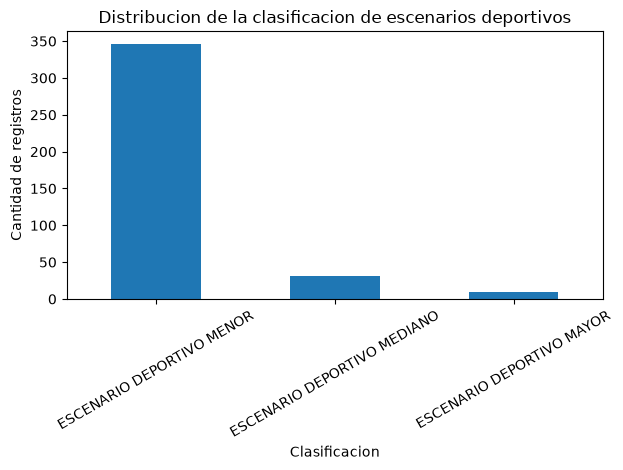

In [96]:
# Contar los registros de cada categoria
distribucion = df["CLASIFICACION"].value_counts()

print("Distribucion de la variable CLASIFICACION:")
display(distribucion)

# Calcular porcentajes
print("\nDistribucion porcentual:")
display((df["CLASIFICACION"].value_counts(normalize=True) * 100).round(2))

# Crear grafica de distribucion
distribucion.plot(
    kind="bar",
    title="Distribucion de la clasificacion de escenarios deportivos",
    xlabel="Clasificacion",
    ylabel="Cantidad de registros"
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Analisis de la relacion entre las variables

Antes de seleccionar las variables predictoras, se analizara la relacion entre la clasificacion de los escenarios deportivos y algunas de sus caracteristicas. Se prestara especial atencion a la variable M2, debido a que representa el area de cada instalacion y podria estar relacionada con la asignacion de las categorias menor, mediano y mayor.

In [97]:
# Analizar el area según cada categoria
resumen_area = df.groupby("CLASIFICACION")["M2"].agg(
    ["count", "min", "mean", "median", "max"]
)

display(resumen_area)

,count,min,mean,median,max
CLASIFICACION,,,,,
ESCENARIO DEPORTIVO MAYOR,10,1404,203954.100000,42727.5,731372
ESCENARIO DEPORTIVO MEDIANO,31,18903,395147.322581,406477.0,894875
ESCENARIO DEPORTIVO MENOR,346,24,21774.193642,4106.5,533735


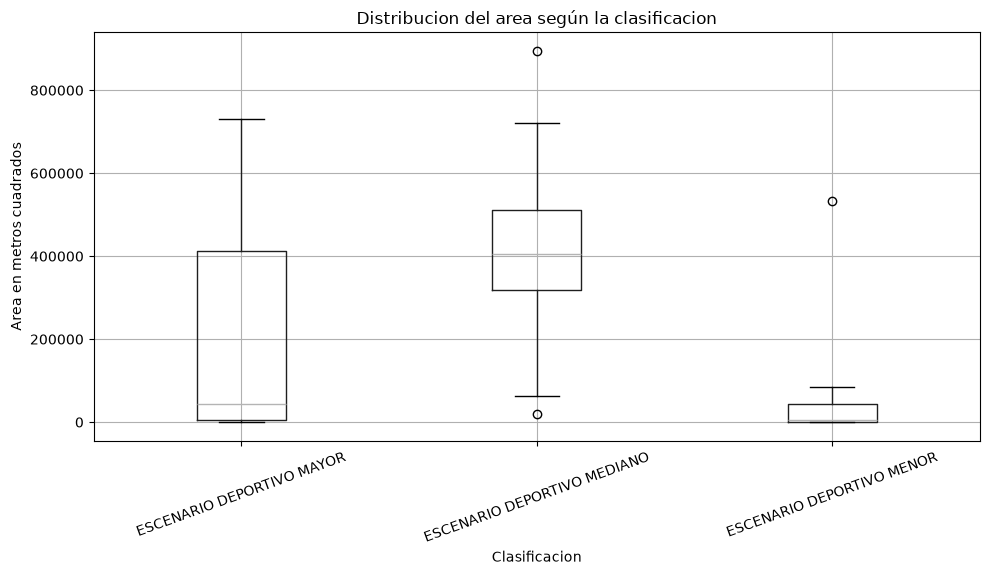

In [98]:
# Comparar las superficies segun la clasificacion
df.boxplot(
    column="M2",
    by="CLASIFICACION",
    figsize=(10, 6)
)

plt.title("Distribucion del area según la clasificacion")
plt.suptitle("")
plt.xlabel("Clasificacion")
plt.ylabel("Area en metros cuadrados")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [99]:
# Crear una tabla cruzada entre tipo y clasificacion
tabla_tipo = pd.crosstab(
    df["TIPO"],
    df["CLASIFICACION"]
)

display(tabla_tipo)

CLASIFICACION,ESCENARIO DEPORTIVO MAYOR,ESCENARIO DEPORTIVO MEDIANO,ESCENARIO DEPORTIVO MENOR
TIPO,,,
CAMPO DE SOFTBOL,0,1,0
CAMPO O ESTADIO DE BEISBOL MENOR,0,1,0
CAMPO SOFTBOL,0,9,0
CAMPOS DE FUTBOL ARENA,0,0,35
CAMPOS O ESTADIOS DE BEISBOL,0,0,1
CAMPOS O ESTADIOS DE SOFTBOL,0,9,13
CANCHA DE FUTBOL SINTETICA,0,0,1
CANCHA SINTETICA,0,0,23
CANCHAS DE GOLITO,0,0,1


### Seleccion de variables

Se definio CLASIFICACION como variable objetivo y se seleccionaron TIPO y LOCALIDAD como variables predictoras, considerando su posible relacion con las caracteristicas de los escenarios deportivos.

Se excluyeron M2 y AREA_HA por el posible riesgo de fuga de informacion, así como las variables identificadoras y referenciales. Tambien se dejo fuera BARRIO debido a su elevada cantidad de categorias. Esta seleccion constituye un modelo inicial, teniendo en cuenta que no se dispone de informacion suficiente sobre los criterios exactos utilizados para asignar las clasificaciones.

In [100]:
y = df["CLASIFICACION"]

X = df[["TIPO", "LOCALIDAD"]]

print("Variables predictoras:")
display(X.head())

print("\nVariable objetivo:")
display(y.head())

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Variables predictoras:


,TIPO,LOCALIDAD
0,PARQUE DEPORTIVO,2
1,ESTADIO,2
2,ESTADIO,2
3,COLISEO,1
4,COLISEO,1



Variable objetivo:


0    ESCENARIO DEPORTIVO MAYOR
1    ESCENARIO DEPORTIVO MAYOR
2    ESCENARIO DEPORTIVO MAYOR
3    ESCENARIO DEPORTIVO MAYOR
4    ESCENARIO DEPORTIVO MAYOR
Name: CLASIFICACION, dtype: str


Dimensiones de X: (387, 2)
Dimensiones de y: (387,)


## 6. Division de los datos en entrenamiento y prueba

Se dividio el conjunto de datos en dos partes: un 80 % para el entrenamiento del modelo y un 20 % para su evaluacion. Se utilizo una division estratificada para mantener una distribucion proporcional de las categorias de la variable objetivo en ambos conjuntos.

In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

print("\nDistribucion de categorias en entrenamiento:")
display(y_train.value_counts())

print("\nDistribucion de categorias en prueba:")
display(y_test.value_counts())

Dimensiones de entrenamiento: (309, 2)
Dimensiones de prueba: (78, 2)

Distribucion de categorias en entrenamiento:


CLASIFICACION
ESCENARIO DEPORTIVO MENOR      276
ESCENARIO DEPORTIVO MEDIANO     25
ESCENARIO DEPORTIVO MAYOR        8
Name: count, dtype: int64


Distribucion de categorias en prueba:


CLASIFICACION
ESCENARIO DEPORTIVO MENOR      70
ESCENARIO DEPORTIVO MEDIANO     6
ESCENARIO DEPORTIVO MAYOR       2
Name: count, dtype: int64

## 7. Preprocesamiento de las variables

Se utilizo OneHotEncoder para transformar las variables categoricas en valores numericos, permitiendo que el algoritmo de clasificacion pueda procesar la informacion. Se configuro handle_unknown="ignore" para evitar errores cuando aparezcan categorias que no estuvieron presentes durante el entrenamiento.

In [102]:
columnas_categoricas = ["TIPO", "LOCALIDAD"]

preprocesamiento = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas)
    ]
)

## 8. Construccion y entrenamiento del modelo

Se implemento un arbol de decision para realizar la clasificacion de los escenarios deportivos. Se establecio una profundidad maxima de tres niveles para controlar la complejidad del modelo y se aplico un ajuste de pesos para considerar el desbalance existente entre las categorías. El preprocesamiento y el clasificador se integraron mediante un Pipeline.

In [103]:
modelo = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("clasificador", DecisionTreeClassifier(
        max_depth=3,
        class_weight="balanced",
        random_state=42
    ))
])

modelo.fit(X_train, y_train)

print("El modelo se entreno correctamente.")

El modelo se entreno correctamente.


## 9. Predicciones y evaluacion del modelo

Una vez entrenado el clasificador, se generaron predicciones utilizando los datos de prueba. Estas predicciones se compararon con las clasificaciones reales para evaluar la capacidad del modelo de identificar correctamente las categorias de los escenarios deportivos.

In [104]:
y_pred = modelo.predict(X_test)

resultados = pd.DataFrame({
    "Clasificacion real": y_test,
    "Clasificacion predicha": y_pred
})

display(resultados.head(10))

,Clasificacion real,Clasificacion predicha
68,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MENOR
230,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MENOR
282,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MEDIANO
314,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MEDIANO
81,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MENOR
90,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MENOR
132,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MENOR
242,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MENOR
364,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MAYOR
337,ESCENARIO DEPORTIVO MENOR,ESCENARIO DEPORTIVO MEDIANO


In [105]:
accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Balanced Accuracy:", round(balanced_accuracy, 4))

print("\nReporte de clasificacion:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7051
Balanced Accuracy: 0.8397

Reporte de clasificacion:
                             precision    recall  f1-score   support

  ESCENARIO DEPORTIVO MAYOR       0.15      1.00      0.27         2
ESCENARIO DEPORTIVO MEDIANO       0.29      0.83      0.43         6
  ESCENARIO DEPORTIVO MENOR       1.00      0.69      0.81        70

                   accuracy                           0.71        78
                  macro avg       0.48      0.84      0.51        78
               weighted avg       0.92      0.71      0.77        78



## 10. Matriz de confusion

Se utilizo una matriz de confusion para visualizar la relacion entre las clasificaciones reales y las predicciones del modelo. Esta representacion permite identificar los aciertos y errores de clasificacion, así como las categorías que presentan mayores dificultades de reconocimiento.

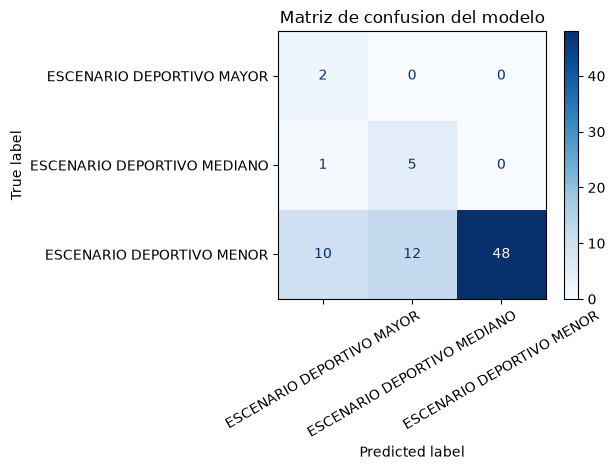

In [106]:
matriz = confusion_matrix(y_test, y_pred, labels=modelo.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

disp.plot(cmap="Blues", xticks_rotation=30)
plt.title("Matriz de confusion del modelo")
plt.tight_layout()
plt.show()

## 11. Comparacion con un modelo de referencia

Se implemento un modelo de referencia mediante DummyClassifier, utilizando la estrategia de predecir siempre la categoria mas frecuente. Esta comparacion permite determinar si el arbol de decision ofrece mejores resultados que una estrategia básica que no identifica relaciones entre las variables predictoras.

In [107]:
from sklearn.dummy import DummyClassifier

modelo_referencia = DummyClassifier(strategy="most_frequent")

modelo_referencia.fit(X_train, y_train)

predicciones_referencia = modelo_referencia.predict(X_test)

accuracy_referencia = accuracy_score(
    y_test, predicciones_referencia
)

balanced_referencia = balanced_accuracy_score(
    y_test, predicciones_referencia
)

comparacion = pd.DataFrame({
    "Modelo": ["Modelo de referencia", "Arbol de decision"],
    "Accuracy": [accuracy_referencia, accuracy],
    "Balanced Accuracy": [balanced_referencia, balanced_accuracy]
})

display(comparacion.round(4))

,Modelo,Accuracy,Balanced Accuracy
0,Modelo de referencia,0.8974,0.3333
1,Arbol de decision,0.7051,0.8397


## 12. Limitaciones del modelo

El desempeño del modelo esta condicionado por el desbalance de las categorias, especialmente por la baja cantidad de escenarios deportivos mayores y medianos. Ademas, las variables predictoras utilizadas no necesariamente representan todos los criterios que intervienen en la clasificacion original de las instalaciones.

Por esta razon, los resultados deben interpretarse como una aproximacion inicial a la clasificacion de los escenarios deportivos y no como un sistema definitivo de categorizacion.